In [1]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from scipy.stats import shapiro

# load the pharmacy sales dataset if df is not already loaded
df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")

# convert columns to appropriate data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["units_sold"] = pd.to_numeric(df["units_sold"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
df["covid_flag"] = pd.to_numeric(df["covid_flag"], errors="coerce")

# remove invalid observations
df = df.dropna(
    subset=["date", "units_sold", "unit_price", "covid_flag"]
).copy()

df = df[
    (df["units_sold"] >= 0) &
    (df["unit_price"] > 0) &
    (df["covid_flag"].isin([0, 1]))
].copy()

# sort records chronologically for time-related diagnostics
df = df.sort_values("date").reset_index(drop=True)

# standardize sales and price
df["sales_scaled"] = (
    df["units_sold"] - df["units_sold"].mean()
) / df["units_sold"].std()

df["price_scaled"] = (
    df["unit_price"] - df["unit_price"].mean()
) / df["unit_price"].std()

# select target and independent variables
X = df[["price_scaled", "covid_flag"]]
X = sm.add_constant(X)
y = df["sales_scaled"]

# fit the ordinary least squares regression model
model = sm.OLS(y, X).fit()

# calculate fitted values and residuals
fitted = model.fittedvalues
residuals = model.resid

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           sales_scaled   R-squared:                       0.098
Model:                            OLS   Adj. R-squared:                  0.098
Method:                 Least Squares   F-statistic:                     9650.
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:27:11   Log-Likelihood:            -2.4339e+05
No. Observations:              177990   AIC:                         4.868e+05
Df Residuals:                  177987   BIC:                         4.868e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.2213      0.003    -80.231   

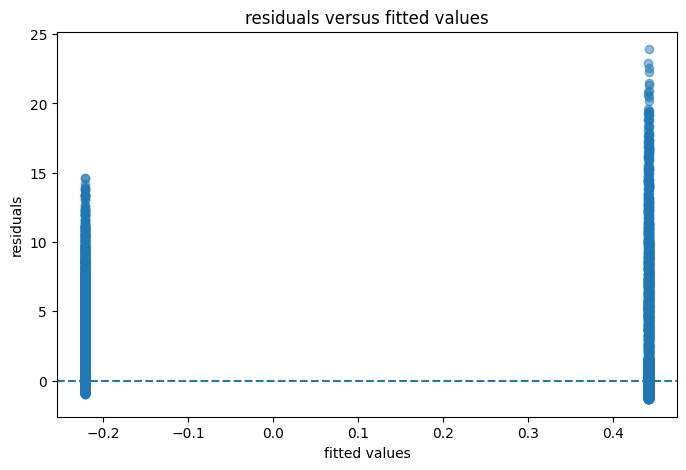

In [2]:
# plot residuals against fitted values
plt.figure(figsize=(8, 5))
plt.scatter(fitted, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("fitted values")
plt.ylabel("residuals")
plt.title("residuals versus fitted values")
plt.show()

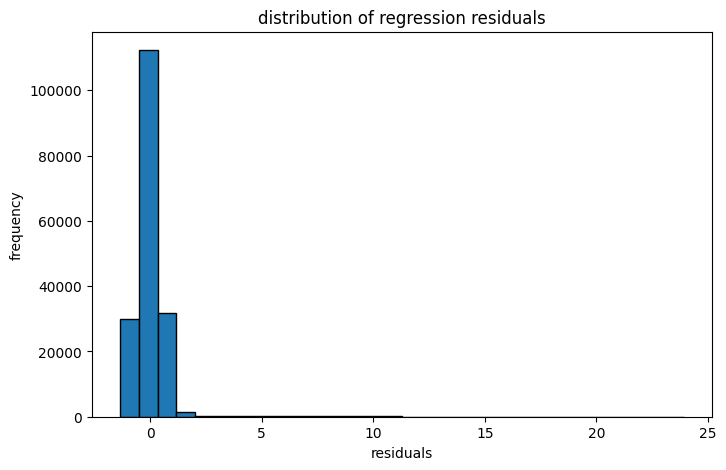

In [3]:
# plot the distribution of residuals
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, edgecolor="black")
plt.xlabel("residuals")
plt.ylabel("frequency")
plt.title("distribution of regression residuals")
plt.show()

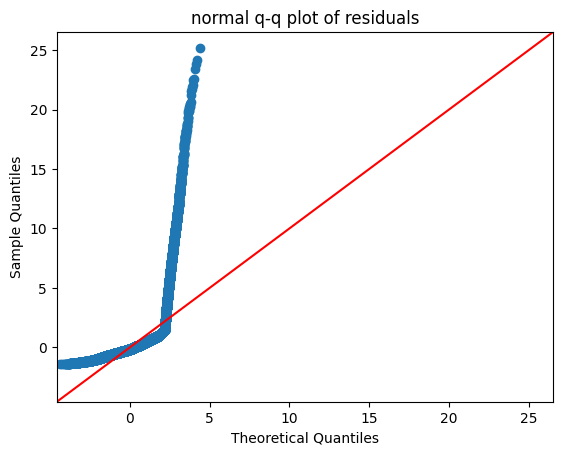

In [4]:
# compare residuals with a normal distribution
sm.qqplot(residuals, line="45", fit=True)
plt.title("normal q-q plot of residuals")
plt.show()

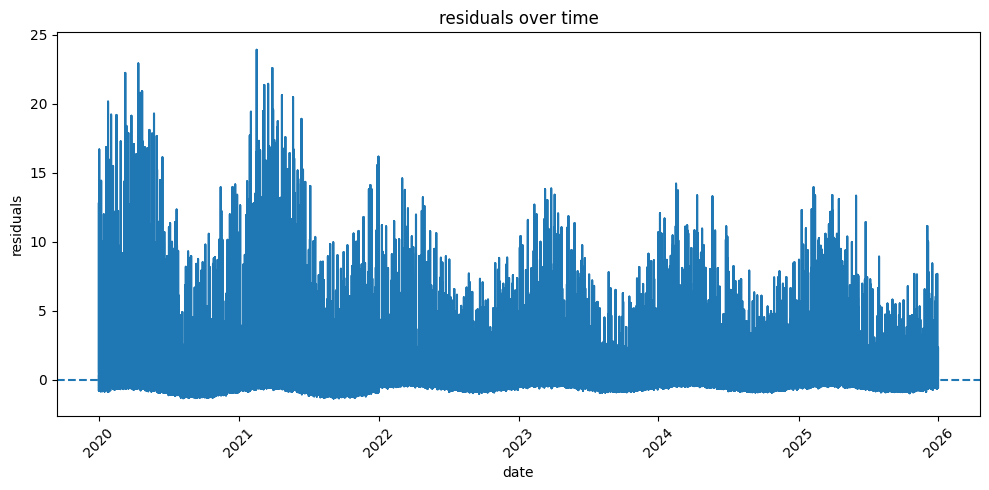

In [5]:
# check residual patterns over time
plt.figure(figsize=(10, 5))
plt.plot(df["date"], residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("date")
plt.ylabel("residuals")
plt.title("residuals over time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
# calculate variance inflation factors for predictors
vif_data = pd.DataFrame()

vif_data["feature"] = X.columns
vif_data["vif"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

# exclude the intercept from interpretation
vif_data = vif_data[vif_data["feature"] != "const"]

print("multicollinearity detection")
print(vif_data)

# interpret vif values
for _, row in vif_data.iterrows():
    if row["vif"] >= 10:
        print(row["feature"], ": high multicollinearity")
    elif row["vif"] >= 5:
        print(row["feature"], ": moderate multicollinearity")
    else:
        print(row["feature"], ": no major multicollinearity indicated")

multicollinearity detection
        feature       vif
1  price_scaled  1.000005
2    covid_flag  1.000005
price_scaled : no major multicollinearity indicated
covid_flag : no major multicollinearity indicated


In [7]:
# test whether residual variance depends on the predictors
bp_test = het_breuschpagan(residuals, X)

bp_labels = [
    "lm statistic",
    "lm p-value",
    "f statistic",
    "f p-value"
]

bp_results = dict(zip(bp_labels, bp_test))

print("breusch-pagan test results")
for name, value in bp_results.items():
    print(name, ":", round(value, 5))

# interpret the test using a 5% significance level
if bp_results["lm p-value"] < 0.05:
    print("evidence of heteroscedasticity")
else:
    print("insufficient evidence of heteroscedasticity")

breusch-pagan test results
lm statistic : 403.12239
lm p-value : 0.0
f statistic : 202.01533
f p-value : 0.0
evidence of heteroscedasticity


In [8]:
# perform the jarque-bera normality test
jb_stat, jb_pvalue, skewness, kurtosis = jarque_bera(residuals)

print("jarque-bera statistic:", round(jb_stat, 4))
print("jarque-bera p-value:", round(jb_pvalue, 5))
print("residual skewness:", round(skewness, 4))
print("residual kurtosis:", round(kurtosis, 4))

# use shapiro-wilk on a subset when the dataset is large
shapiro_sample = residuals.sample(
    n=min(5000, len(residuals)),
    random_state=42
)

shapiro_stat, shapiro_pvalue = shapiro(shapiro_sample)

print("shapiro-wilk statistic:", round(shapiro_stat, 4))
print("shapiro-wilk p-value:", round(shapiro_pvalue, 5))

# interpret the jarque-bera result
if jb_pvalue < 0.05:
    print("residual normality may be violated")
else:
    print("insufficient evidence against residual normality")

jarque-bera statistic: 92024327.3045
jarque-bera p-value: 0.0
residual skewness: 8.4019
residual kurtosis: 113.1186
shapiro-wilk statistic: 0.4999
shapiro-wilk p-value: 0.0
residual normality may be violated


In [9]:
# calculate the durbin-watson statistic
dw_stat = durbin_watson(residuals)

print("durbin-watson statistic:", round(dw_stat, 4))

# provide a basic interpretation
if dw_stat < 1.5:
    print("possible positive residual autocorrelation")
elif dw_stat > 2.5:
    print("possible negative residual autocorrelation")
else:
    print("no strong autocorrelation signal from this rough check")

durbin-watson statistic: 1.7484
no strong autocorrelation signal from this rough check


In [10]:
# summarize key regression diagnostic results
print("\nregression diagnostic report")

print("observations:", int(model.nobs))
print("r-squared:", round(model.rsquared, 4))
print("adjusted r-squared:", round(model.rsquared_adj, 4))

print("breusch-pagan p-value:", round(bp_results["lm p-value"], 5))
print("jarque-bera p-value:", round(jb_pvalue, 5))
print("durbin-watson statistic:", round(dw_stat, 4))

print("maximum predictor vif:", round(vif_data["vif"].max(), 4))

print("\ninterpretation")

if bp_results["lm p-value"] < 0.05:
    print("- investigate non-constant residual variance")
else:
    print("- no significant heteroscedasticity detected by this test")

if jb_pvalue < 0.05:
    print("- residual normality may be violated")
else:
    print("- no significant departure from normality detected by this test")

if vif_data["vif"].max() >= 5:
    print("- investigate predictors with elevated vif")
else:
    print("- no major multicollinearity indicated by vif")

if dw_stat < 1.5 or dw_stat > 2.5:
    print("- investigate residual autocorrelation")
else:
    print("- durbin-watson does not indicate strong autocorrelation")

print("\nreview all diagnostic plots before accepting the model")


regression diagnostic report
observations: 177990
r-squared: 0.0978
adjusted r-squared: 0.0978
breusch-pagan p-value: 0.0
jarque-bera p-value: 0.0
durbin-watson statistic: 1.7484
maximum predictor vif: 1.0

interpretation
- investigate non-constant residual variance
- residual normality may be violated
- no major multicollinearity indicated by vif
- durbin-watson does not indicate strong autocorrelation

review all diagnostic plots before accepting the model
